# Filtering and Blurring

Filtering replaces each pixel with a combination of its neighbours, defined by a small matrix called a kernel. Blurring reduces noise and detail; sharpening does the opposite. This notebook covers 2D convolution, the standard blur family - box, Gaussian, median, bilateral - and how to choose between them.

## Setup

We import OpenCV (`cv2`), NumPy and Matplotlib. In these notebooks images are displayed with Matplotlib so the code runs everywhere, including servers without a screen. The classic OpenCV window functions are explained where they belong, with example code you can run on your own machine.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(image, title="", cmap=None):
    """Display a BGR (or single-channel) image with matplotlib - works in any environment."""
    if len(image.shape) == 2:
        plt.imshow(image, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


OpenCV version: 4.10.0


## 2D convolution with filter2D

`cv2.filter2D` slides a kernel over the image and writes the weighted sum at each position. An all-ones kernel divided by its size is a plain average (box) blur. A kernel with a strong centre and negative surroundings sharpens.

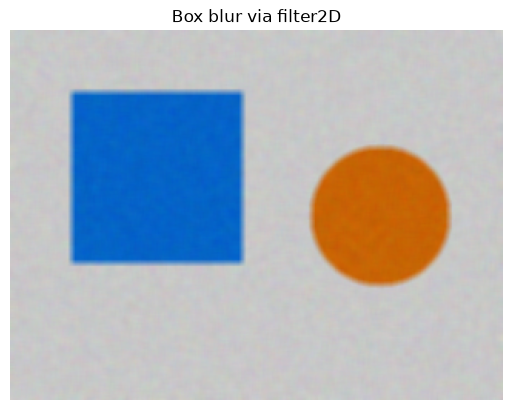

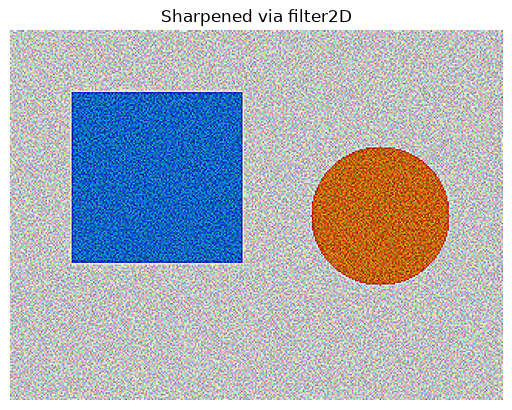

In [2]:
img = cv2.imread("../assets/noisy_image.png")
box_kernel = np.ones((5, 5), np.float32) / 25
box_blur = cv2.filter2D(img, -1, box_kernel)
sharpen_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], np.float32)
sharpened = cv2.filter2D(img, -1, sharpen_kernel)
show(box_blur, "Box blur via filter2D")
show(sharpened, "Sharpened via filter2D")

## Gaussian blur - the default smoothing

Gaussian blur weights neighbours by distance from the centre, so it looks natural and has no harsh artefacts. Kernel sizes must be odd. It is the standard pre-processing step before edge detection. The third parameter is sigma - 0 lets OpenCV compute it from the kernel size.

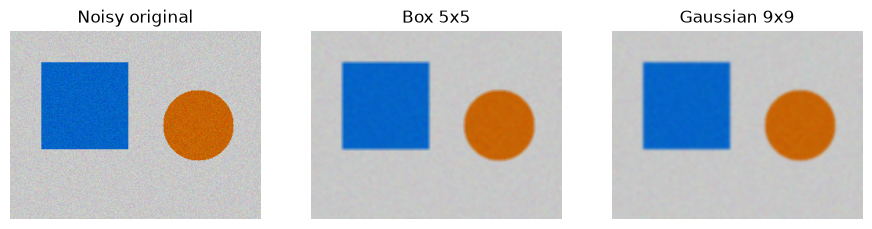

In [3]:
gauss = cv2.GaussianBlur(img, (9, 9), 0)
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, im, name in zip(axes, (img, box_blur, gauss), ("Noisy original", "Box 5x5", "Gaussian 9x9")):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(name); ax.axis("off")
plt.show()

## Median blur - the salt-and-pepper killer

Median blur replaces each pixel with the median of its neighbourhood. It removes spike (salt-and-pepper) noise completely while keeping edges far better than averaging filters. Kernel size is a single odd integer.

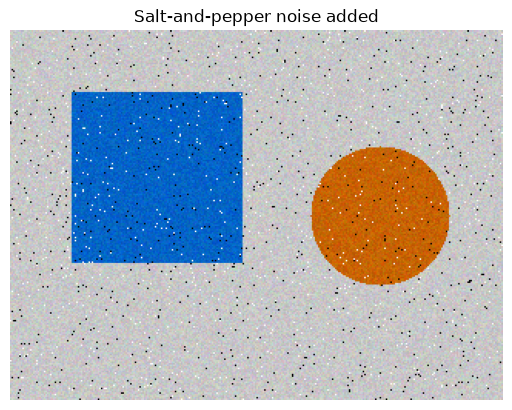

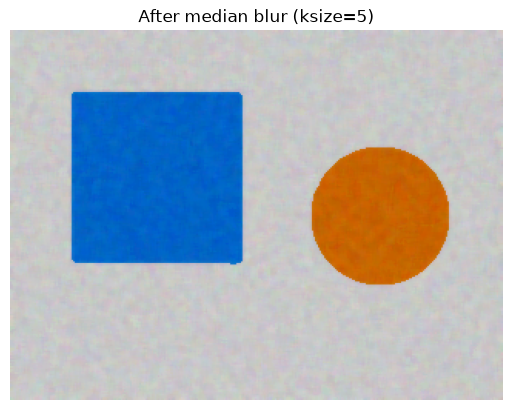

In [4]:
sp = img.copy()
rng = np.random.default_rng(3)
coords = rng.integers(0, sp.shape[0], 800), rng.integers(0, sp.shape[1], 800)
sp[coords] = 255
coords = rng.integers(0, sp.shape[0], 800), rng.integers(0, sp.shape[1], 800)
sp[coords] = 0
median = cv2.medianBlur(sp, 5)
show(sp, "Salt-and-pepper noise added")
show(median, "After median blur (ksize=5)")

## Bilateral filtering - smoothing that keeps edges

Bilateral filtering averages only neighbours that are close in space AND similar in colour, so flat areas become smooth while edges stay sharp. It is slower but is the base of cartoon and beautification effects. Parameters: diameter, sigmaColor, sigmaSpace.

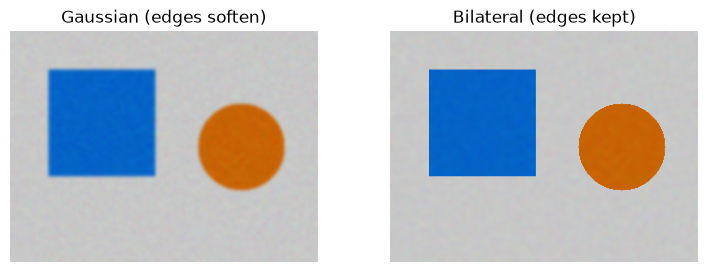

In [5]:
bilateral = cv2.bilateralFilter(img, 9, 75, 75)
gauss2 = cv2.GaussianBlur(img, (9, 9), 0)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, im, name in zip(axes, (gauss2, bilateral), ("Gaussian (edges soften)", "Bilateral (edges kept)")):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(name); ax.axis("off")
plt.show()

## Blur strength, kernel size and measuring sharpness

Bigger kernels = stronger blur = more detail lost. A quick sharpness measure is the variance of the Laplacian: sharp images have many strong edges (high variance), blurred images have few. This score is used in practice to reject blurry photos automatically.

In [6]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
for k in (3, 9, 21):
    blurred = cv2.GaussianBlur(gray, (k, k), 0)
    score = cv2.Laplacian(blurred, cv2.CV_64F).var()
    print(f"Gaussian kernel {k:2d} -> Laplacian variance (sharpness): {score:8.1f}")

Gaussian kernel  3 -> Laplacian variance (sharpness):     52.0
Gaussian kernel  9 -> Laplacian variance (sharpness):      4.9
Gaussian kernel 21 -> Laplacian variance (sharpness):      1.1


## Erosion and dilation preview as filters

Morphology (notebook 08 in full) can also be understood as filtering with a structuring element: erosion keeps the minimum, dilation keeps the maximum in each neighbourhood. A single erosion cleans isolated white specks from a mask.

White pixels before/after erosion: 60756 -> 57371


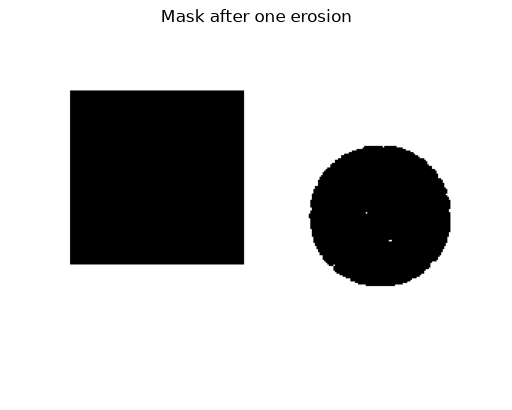

In [7]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
_, mask = cv2.threshold(gray, 120, 255, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
cleaned = cv2.erode(mask, kernel, iterations=1)
print("White pixels before/after erosion:", int((mask > 0).sum()), "->", int((cleaned > 0).sum()))
show(cleaned, "Mask after one erosion")

## Key Points

- filter2D applies any custom kernel; kernel weights that sum to 1 preserve brightness.
- Gaussian blur is the natural-looking default and the standard step before edge detection.
- Median blur removes salt-and-pepper noise while keeping edges.
- Bilateral filtering smooths flat areas but preserves edges - slower, used for effects.
- Variance of the Laplacian is a practical blur/sharpness score.

## Mini Task

1. Add salt-and-pepper noise to `test_image.png` and remove it with median blur; compare with Gaussian blur visually.
2. Write a custom 3x3 emboss kernel and apply it with filter2D.
3. Print the Laplacian-variance sharpness of the original vs a strongly blurred copy.